# 08 · Physics-informed neural networks (1D): Burgers' shock
**Level: Expert** · ~25 min (training ≈ 7 min on CPU) · *Track: Scientific ML*

A **PINN** represents the field as a neural network $u_\theta(x,t)$ and trains it to satisfy the
PDE, the initial/boundary conditions **and** the sensor data at the same time:

$$\mathcal L(\theta) = \underbrace{\tfrac{1}{N_r}\textstyle\sum |\mathcal R[u_\theta](x_i,t_i)|^2}_{\text{physics residual}} + w_0\underbrace{\tfrac{1}{N_0}\textstyle\sum|u_\theta(x,0)-u_0|^2}_{\text{initial condition}} + w_b\underbrace{\tfrac{1}{N_b}\textstyle\sum|u_\theta(\pm1,t)|^2}_{\text{boundaries}} + w_d\underbrace{\tfrac{1}{N_d}\textstyle\sum|u_\theta(x_j,t_j)-y_j|^2}_{\text{sensors}}$$

Derivatives in $\mathcal R$ come from **automatic differentiation**, so no mesh is needed. Unknown
physical parameters can simply be added to $\theta$: the same training then solves the **inverse
problem**. For a twin this means a single framework for state reconstruction plus calibration.

**Test problem:** the viscous Burgers equation, a 1D model of nonlinear transport that forms a
near-shock:
$$u_t + u\,u_x = \nu\,u_{xx},\quad x\in[-1,1],\ t\in[0,1],\quad u(x,0)=-\sin(\pi x),\ u(\pm1,t)=0,\ \nu=0.01/\pi.$$

**Plan:** (1) exact reference solution, (2) forward PINN, (3) diagnosing the PINN, (4) inverse twin:
reconstruct the field *and* identify $\nu$ from 10 noisy sensors, (5) expert practice notes.

In [1]:
import sys; sys.path.insert(0, "..")
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
from IPython.display import HTML
from dtwin import viz
from dtwin.solvers import burgers_exact
from dtwin.pinn import MLP, grad, tensor, train, set_seed
viz.set_style()
set_seed(0)
rng = np.random.default_rng(0)
NU = 0.01 / np.pi
torch.set_num_threads(max(1, torch.get_num_threads()))

## 1. Ground truth via the Cole-Hopf transform
Burgers' equation linearises into the heat equation under $u=-2\nu\,\partial_x\log\phi$, which
gives an exact integral solution. We evaluate it by quadrature (`dtwin.solvers.burgers_exact`).

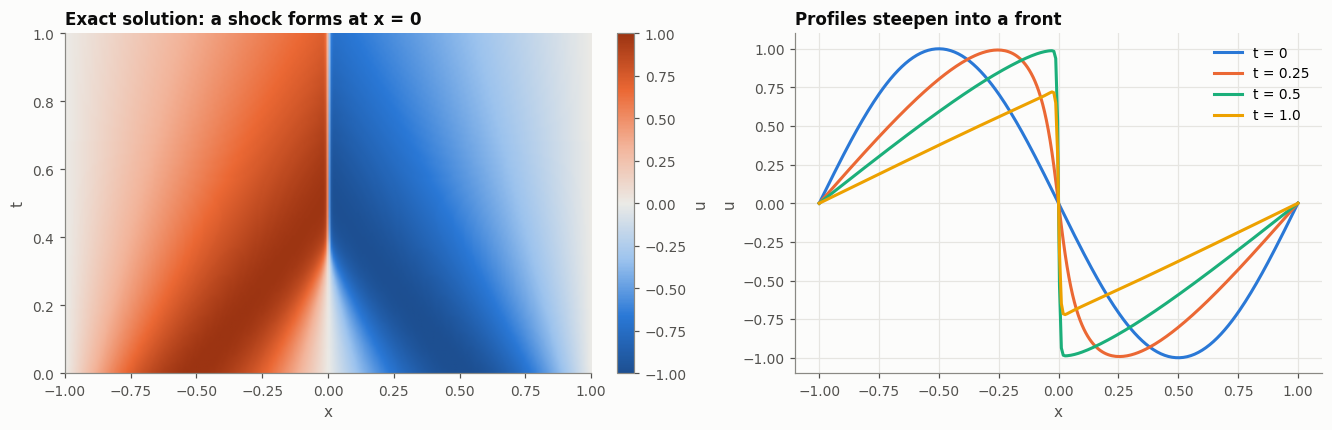

In [2]:
xg, tg = np.linspace(-1, 1, 256), np.linspace(0, 1, 101)
U_exact = burgers_exact(xg, tg, NU)
XX, TT = np.meshgrid(xg, tg)
grid_pts = tensor(np.c_[XX.ravel(), TT.ravel()])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
viz.spacetime(axes[0], U_exact, xg, tg, cmap=viz.DIVERGING, vmin=-1, vmax=1, label="u")
axes[0].set_title("Exact solution: a shock forms at x = 0")
for i, tk in enumerate([0, 0.25, 0.5, 1.0]):
    axes[1].plot(xg, U_exact[np.argmin(abs(tg - tk))], color=viz.SERIES[i], label=f"t = {tk}")
axes[1].set(xlabel="x", ylabel="u", title="Profiles steepen into a front")
axes[1].legend()
plt.show()

## 2. Forward PINN
* **Network:** 5 hidden layers × 40 tanh units; inputs rescaled to $[-1,1]$ inside the model.
* **Collocation points:** 8,000 random $(x,t)$ points where the residual is enforced.
* **Optimiser:** Adam to get into the right basin, then L-BFGS to polish (standard practice).

In [3]:
def residual(net, X, nu):
    u = net(X)
    du = grad(u, X)
    ux, ut = du[:, :1], du[:, 1:]
    uxx = grad(ux, X)[:, :1]
    return ut + u * ux - nu * uxx

Xc = tensor(np.c_[rng.uniform(-1, 1, 8000), rng.uniform(0, 1, 8000)], requires_grad=True)
x0 = rng.uniform(-1, 1, 256)
X0, U0 = tensor(np.c_[x0, np.zeros_like(x0)]), tensor(-np.sin(np.pi * x0)[:, None])
tb = rng.uniform(0, 1, 200)
Xb = tensor(np.c_[np.r_[-np.ones(100), np.ones(100)], tb])

net = MLP(2, 1, width=40, depth=5, lb=[-1, 0], ub=[1, 1])
snapshots = {}

def forward_loss():
    lr = (residual(net, Xc, NU) ** 2).mean()
    l0 = ((net(X0) - U0) ** 2).mean()
    lb = (net(Xb) ** 2).mean()
    return lr + 10 * l0 + 10 * lb, {"pde": lr.item(), "ic": l0.item(), "bc": lb.item()}

def snap(hist):
    it = len(hist["total"])
    if it in (100, 1000, 3000):
        with torch.no_grad():
            snapshots[it] = net(grid_pts).numpy().reshape(TT.shape)

t0 = time.time()
hist = train(forward_loss, list(net.parameters()), n_adam=3000, lr=2e-3, n_lbfgs=1500,
             log_every=1000, callback=snap)
with torch.no_grad():
    U_pinn = net(grid_pts).numpy().reshape(TT.shape)
snapshots["final"] = U_pinn
rel = np.linalg.norm(U_pinn - U_exact) / np.linalg.norm(U_exact)
print(f"relative L2 error {rel:.2e}   ({time.time() - t0:.0f}s)")

adam     0  loss 4.610e+00  pde 3.41e-04  ic 4.58e-01  bc 2.90e-03  (0s)


adam  1000  loss 1.958e-01  pde 1.63e-01  ic 3.15e-03  bc 1.01e-04  (29s)


adam  2000  loss 1.237e-01  pde 1.03e-01  ic 1.99e-03  bc 3.29e-05  (57s)


adam  2999  loss 2.005e-02  pde 1.63e-02  ic 3.61e-04  bc 1.02e-05  (87s)


lbfgs done  loss 6.295e-05  (139s)
relative L2 error 7.32e-03   (140s)


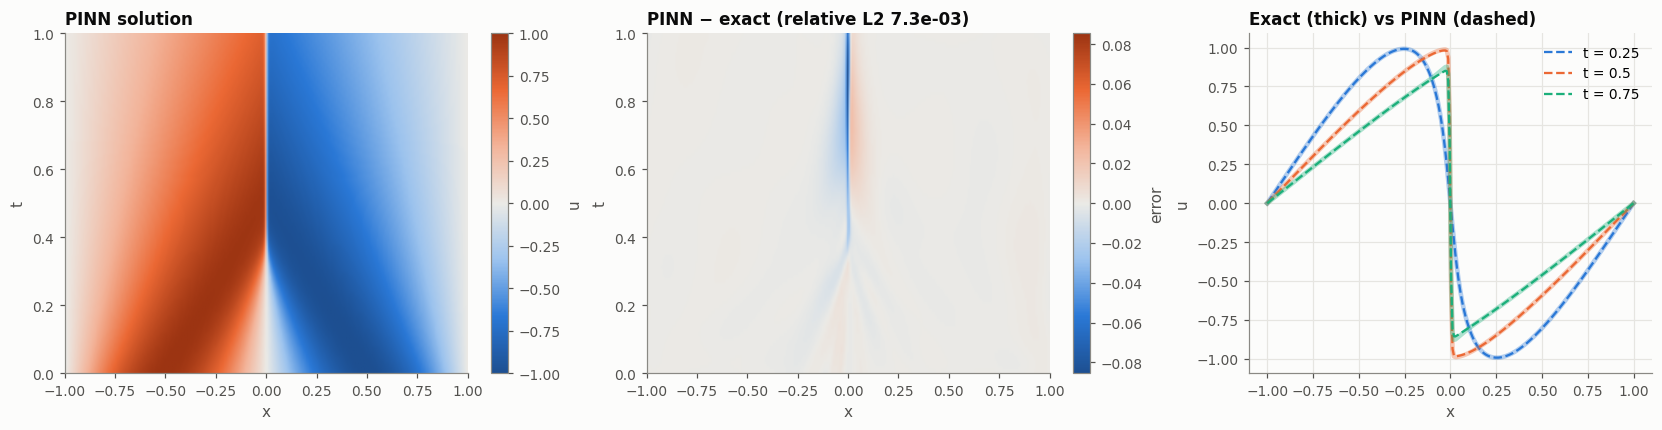

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), constrained_layout=True)
viz.spacetime(axes[0], U_pinn, xg, tg, cmap=viz.DIVERGING, vmin=-1, vmax=1, label="u")
axes[0].set_title("PINN solution")
err = U_pinn - U_exact
lim = np.abs(err).max()
viz.spacetime(axes[1], err, xg, tg, cmap=viz.DIVERGING, vmin=-lim, vmax=lim, label="error")
axes[1].set_title(f"PINN − exact (relative L2 {rel:.1e})")
for i, tk in enumerate([0.25, 0.5, 0.75]):
    k = np.argmin(abs(tg - tk))
    axes[2].plot(xg, U_exact[k], color=viz.SERIES[i], lw=3, alpha=0.35)
    axes[2].plot(xg, U_pinn[k], "--", color=viz.SERIES[i], lw=1.5, label=f"t = {tk}")
axes[2].set(xlabel="x", ylabel="u", title="Exact (thick) vs PINN (dashed)")
axes[2].legend()
viz.save(fig, "08_pinn_burgers.png")
plt.show()

## 3. Diagnosing a PINN
Three diagnostics every practitioner should look at:
1. **Loss components** separately: a low total can hide one term that never converged.
2. **How the solution forms during training:** PINNs learn smooth, low-frequency parts first
   (*spectral bias*) and the sharp front last.
3. **The residual map:** where the physics is still violated. Here, at the shock.

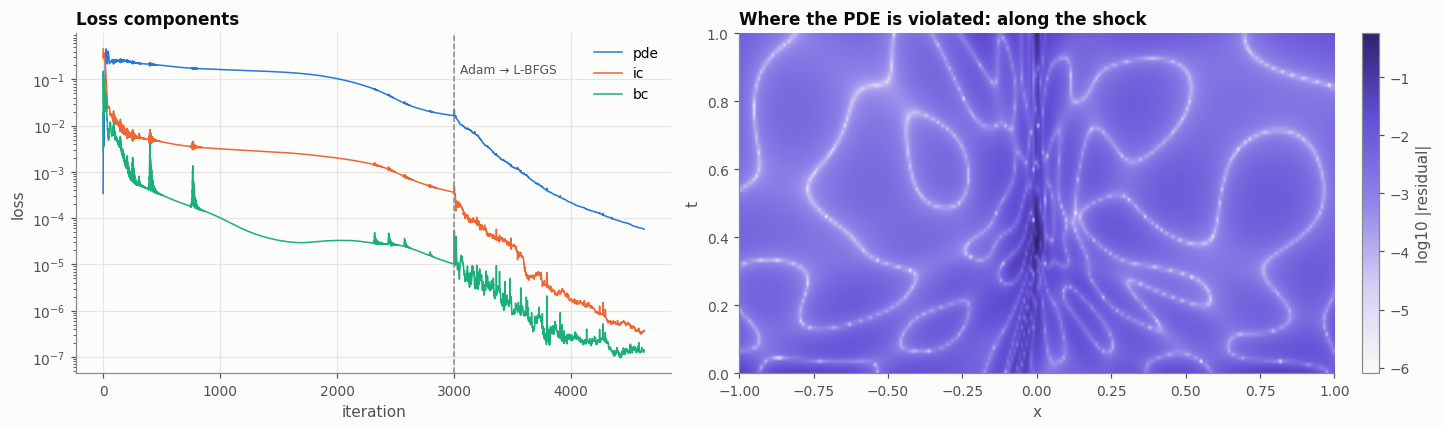

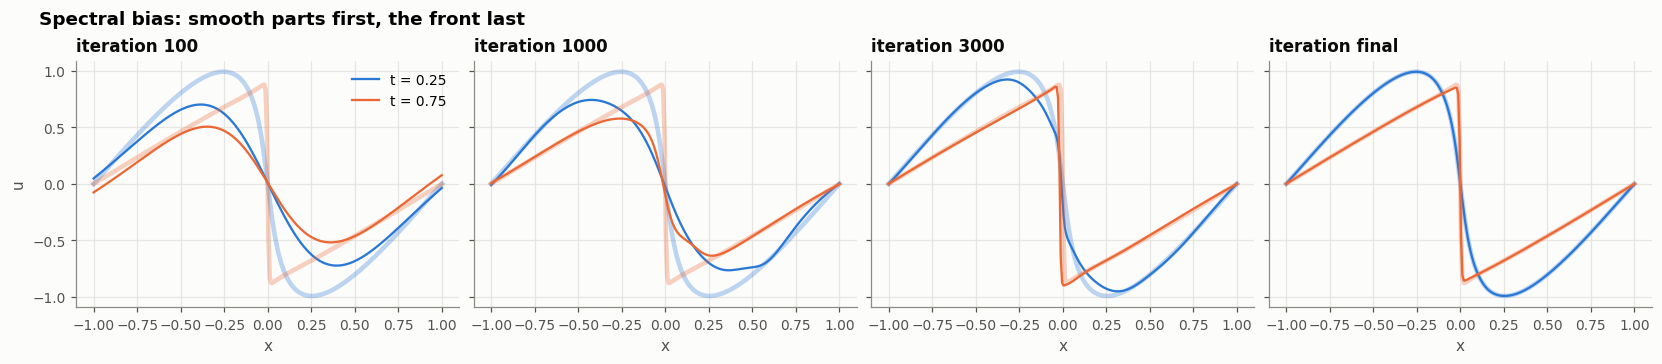

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), constrained_layout=True)
it = np.arange(len(hist["total"]))
for i, k in enumerate(["pde", "ic", "bc"]):
    axes[0].semilogy(it, hist[k], color=viz.SERIES[i], lw=1, label=k)
axes[0].axvline(3000, color=viz.MUTED, ls="--", lw=1)
axes[0].text(3050, max(hist["ic"]) * 0.3, "Adam → L-BFGS", color=viz.INK2, fontsize=8)
axes[0].set(xlabel="iteration", ylabel="loss", title="Loss components")
axes[0].legend()
Xg = tensor(np.c_[XX.ravel(), TT.ravel()], requires_grad=True)
res = residual(net, Xg, NU).detach().numpy().reshape(TT.shape)
viz.spacetime(axes[1], np.log10(np.abs(res) + 1e-8), xg, tg, cmap=viz.UNCERTAINTY, label="log10 |residual|")
axes[1].set_title("Where the PDE is violated: along the shock")
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), constrained_layout=True, sharey=True)
for ax, (k, U) in zip(axes, snapshots.items()):
    for i, tk in enumerate([0.25, 0.75]):
        j = np.argmin(abs(tg - tk))
        ax.plot(xg, U_exact[j], color=viz.SERIES[i], lw=3, alpha=0.3)
        ax.plot(xg, U[j], color=viz.SERIES[i], lw=1.5, label=f"t = {tk}")
    ax.set(title=f"iteration {k}", xlabel="x")
axes[0].set_ylabel("u")
axes[0].legend()
fig.suptitle("Spectral bias: smooth parts first, the front last", x=0.02, ha="left", fontweight="semibold")
plt.show()

## 4. The inverse twin: field + viscosity from 10 sensors
Now the real twin task. We **don't know ν**. We have 10 fixed sensors, each recording 50 noisy
readings (σ = 0.02) over time. The PINN must reconstruct $u(x,t)$ everywhere and identify $\nu$.
$\nu$ becomes a trainable parameter, learned in log-space (positive, unknown scale) with its own,
larger learning rate. The initial guess is $\nu=0.05$, 16× too large.

In [6]:
sens_x = np.linspace(-0.9, 0.9, 10)
sens_t = np.linspace(0, 1, 50)
ST, SX = np.meshgrid(sens_t, sens_x, indexing="ij")
Xd = tensor(np.c_[SX.ravel(), ST.ravel()])

def run_inverse(nu_true, nu_init, n_adam=3000, n_lbfgs=2000, seed=1):
    set_seed(seed)
    Y_noisy = burgers_exact(sens_x, sens_t, nu_true) + 0.02 * rng.standard_normal((sens_t.size, sens_x.size))
    Yd = tensor(Y_noisy.ravel()[:, None])
    net_i = MLP(2, 1, width=40, depth=5, lb=[-1, 0], ub=[1, 1])
    log_nu = torch.nn.Parameter(torch.tensor(np.log(nu_init), dtype=torch.float32))

    def loss():
        nu = torch.exp(log_nu)
        lr = (residual(net_i, Xc, nu) ** 2).mean()
        l0 = ((net_i(X0) - U0) ** 2).mean()
        lb = (net_i(Xb) ** 2).mean()
        ld = ((net_i(Xd) - Yd) ** 2).mean()
        return lr + 10 * l0 + 10 * lb + 10 * ld, {"pde": lr.item(), "data": ld.item(), "nu": nu.item()}

    groups = [{"params": list(net_i.parameters())}, {"params": [log_nu], "lr": 2e-2}]
    h = train(loss, groups, n_adam=n_adam, lr=2e-3, n_lbfgs=n_lbfgs, log_every=1000)
    with torch.no_grad():
        U = net_i(grid_pts).numpy().reshape(TT.shape)
    return dict(U=U, nu=h["nu"], Y=Y_noisy, nu_hat=h["nu"][-1], nu_true=nu_true)

t0 = time.time()
shock = run_inverse(NU, 0.05)
U_inv, Y_noisy, nu_hat = shock["U"], shock["Y"], shock["nu_hat"]
rel_inv = np.linalg.norm(U_inv - U_exact) / np.linalg.norm(U_exact)
print(f"identified nu = {nu_hat:.5f}  (true {NU:.5f}, error {abs(nu_hat/NU-1)*100:.0f}%)   "
      f"field rel L2 = {rel_inv:.2e}   ({time.time() - t0:.0f}s)")

adam     0  loss 9.002e+00  pde 1.15e-01  data 3.82e-01  nu 5.00e-02  (0s)


adam  1000  loss 1.569e-02  pde 6.60e-03  data 7.63e-04  nu 2.07e-02  (86s)


adam  2000  loss 9.115e-03  pde 2.89e-03  data 5.71e-04  nu 1.74e-02  (182s)


adam  2999  loss 7.651e-03  pde 2.11e-03  data 5.22e-04  nu 1.60e-02  (307s)


lbfgs done  loss 3.911e-03  (457s)
identified nu = 0.00438  (true 0.00318, error 38%)   field rel L2 = 2.07e-02   (457s)


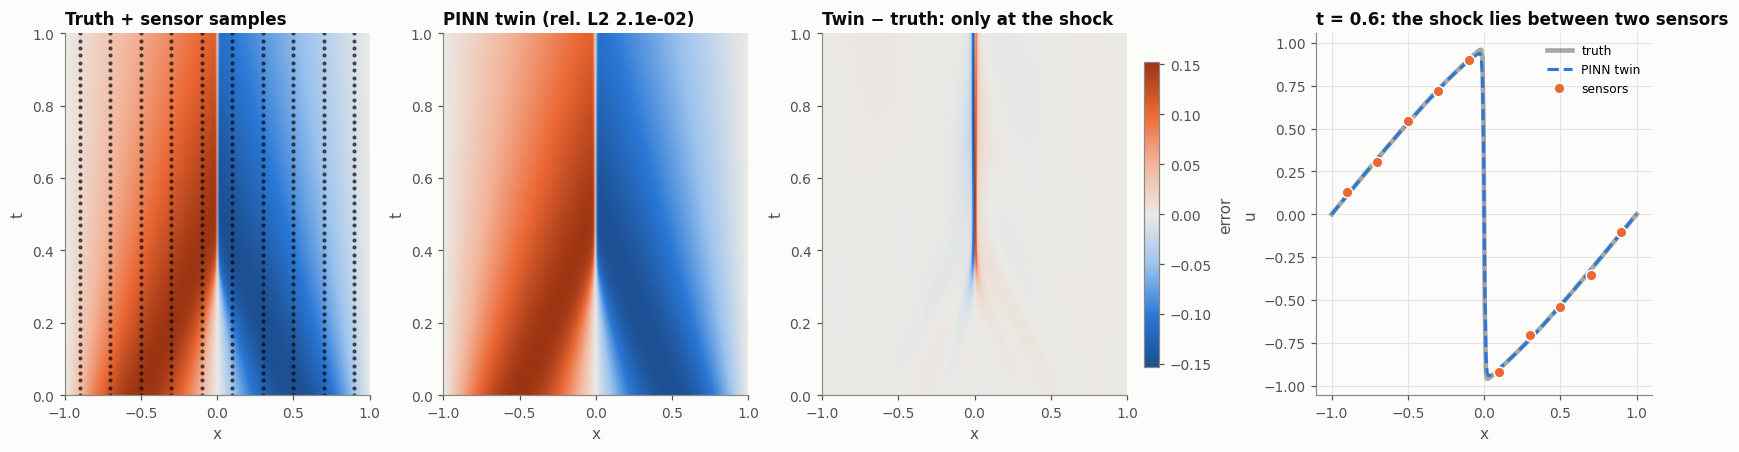

In [7]:
fig = plt.figure(figsize=(15, 4), constrained_layout=True)
gs = fig.add_gridspec(1, 4, width_ratios=[1, 1, 1, 1.1])
ax = fig.add_subplot(gs[0])
viz.spacetime(ax, U_exact, xg, tg, cmap=viz.DIVERGING, vmin=-1, vmax=1, cbar=False)
ax.scatter(SX.ravel(), ST.ravel(), s=3, color=viz.INK, alpha=0.6)
ax.set_title("Truth + sensor samples")
ax = fig.add_subplot(gs[1])
viz.spacetime(ax, U_inv, xg, tg, cmap=viz.DIVERGING, vmin=-1, vmax=1, cbar=False)
ax.set_title(f"PINN twin (rel. L2 {rel_inv:.1e})")
ax = fig.add_subplot(gs[2])
e = U_inv - U_exact
viz.spacetime(ax, e, xg, tg, cmap=viz.DIVERGING, vmin=-np.abs(e).max(), vmax=np.abs(e).max(), label="error")
ax.set_title("Twin − truth: only at the shock")
ax = fig.add_subplot(gs[3])
k = np.argmin(abs(tg - 0.6))
ax.plot(xg, U_exact[k], color=viz.TRUTH, lw=3, alpha=0.35, label="truth")
ax.plot(xg, U_inv[k], "--", color=viz.TWIN, label="PINN twin")
j = np.argmin(abs(sens_t - 0.6))
ax.plot(sens_x, Y_noisy[j], "o", color=viz.DATA, mec="white", ms=7, label="sensors")
ax.set(xlabel="x", ylabel="u", title="t = 0.6: the shock lies between two sensors")
ax.legend(fontsize=8)
viz.save(fig, "08_pinn_inverse.png")
plt.show()

The **field** is reconstructed very well, but $\hat\nu$ is noticeably off. That's not a training
bug; it is **physics**. For small $\nu$, Burgers' equation is in the *inviscid limit*: the energy
dissipated at a shock is $\approx \Delta u^3/12$ per unit time, **independent of ν**. Viscosity only
sets the shock thickness ($\sim 2\nu/\Delta u \approx 0.003$), far below the 0.2 sensor spacing. Many
values of ν explain the data equally well: ν is **practically non-identifiable** from these sensors
(compare the flat valleys of notebook 03).

**Check:** repeat in a smoother regime, $\nu^\star = 0.1/\pi$, where the front is ~0.06 wide and
visible to the sensors. Start from a guess 6× too *small* this time.

adam     0  loss 1.021e+01  pde 2.15e-01  data 3.80e-01  nu 5.00e-03  (0s)


adam  1000  loss 1.521e-02  pde 7.42e-03  data 4.55e-04  nu 3.33e-02  (45s)


adam  1999  loss 7.554e-03  pde 2.66e-03  data 4.04e-04  nu 3.26e-02  (88s)


lbfgs done  loss 3.894e-03  (146s)
smooth regime: nu = 0.0316 (true 0.0318, error 0.7%)  (146s)


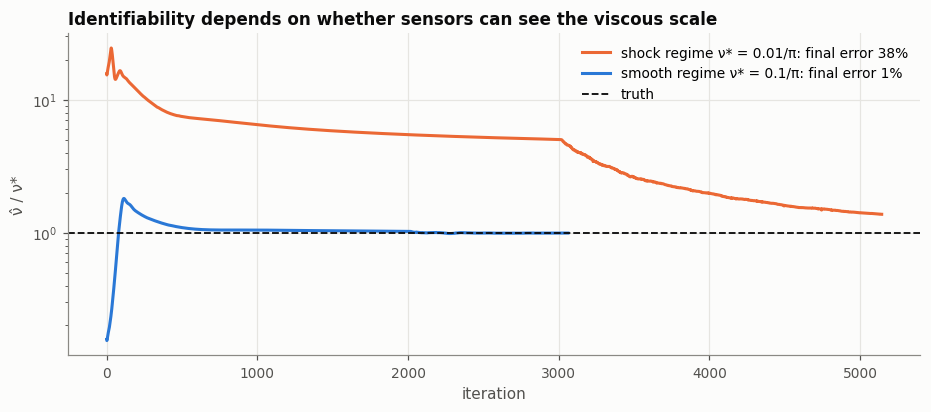

In [8]:
t0 = time.time()
smooth = run_inverse(0.1 / np.pi, 0.005, n_adam=2000, n_lbfgs=1000, seed=2)
print(f"smooth regime: nu = {smooth['nu_hat']:.4f} (true {0.1/np.pi:.4f}, "
      f"error {abs(smooth['nu_hat']/smooth['nu_true']-1)*100:.1f}%)  ({time.time()-t0:.0f}s)")

fig, ax = plt.subplots(figsize=(10, 3.8))
for case, col, name in [(shock, viz.ORANGE, "shock regime ν* = 0.01/π"),
                        (smooth, viz.BLUE, "smooth regime ν* = 0.1/π")]:
    ax.plot(np.array(case["nu"]) / case["nu_true"], color=col, label=f"{name}: final error "
            f"{abs(case['nu_hat']/case['nu_true']-1)*100:.0f}%")
ax.axhline(1, color=viz.TRUTH, ls="--", lw=1.2, label="truth")
ax.set(yscale="log", xlabel="iteration", ylabel="ν̂ / ν*",
       title="Identifiability depends on whether sensors can see the viscous scale")
ax.legend()
plt.show()

In [9]:
idx = np.arange(0, len(tg), 2)
jdx = [np.argmin(abs(sens_t - tt)) for tt in tg[idx]]
anim = viz.animate_1d(xg, [U_exact[idx], U_inv[idx]], tg[idx], labels=["truth", "PINN twin"],
                      colors=[viz.TRUTH, viz.TWIN], styles=["-", "--"], points=(sens_x, Y_noisy[jdx]),
                      title="Burgers twin", ylim=(-1.2, 1.2))
HTML(anim.to_jshtml())

## 5. Expert practice notes
| Issue | Symptom | Remedies |
|---|---|---|
| Loss imbalance | one term stalls while others drop | fixed weights (as here), adaptive weights (gradient-norm balancing, NTK, self-adaptive) |
| Spectral bias | sharp fronts learned last or never | Fourier features, residual-based adaptive sampling (RAR), more points near fronts |
| Causality violation | late times fitted before early ones | causal weighting / time-marching windows |
| Stiff optimisation | Adam plateaus | Adam → L-BFGS, learning-rate decay, float64 for the last phase |
| Unscaled inputs/outputs | slow or no training | normalise inputs to $[-1,1]$ (done in `MLP`), non-dimensionalise the PDE |

**PINN vs. Kalman filter as twin engines:** a PINN does smoothing over a whole time window
(past and future data at once) and needs no mesh. It handles nonlinear PDEs and parameters
naturally, but must be retrained or fine-tuned as new data arrive and has no built-in
uncertainty. Filters are sequential, cheap per step, and quantify uncertainty. Hybrids (PINN
surrogate + EnKF, or ensembles of PINNs) are an active research area.

**Exercises**
1. Remove the initial-condition loss in the inverse problem. Can the sensors alone pin down the solution?
2. Add 6 sensors clustered within ±0.02 of the shock. Does $\nu$ become identifiable in the shock regime?
3. Add residual-based adaptive refinement: every 500 iterations add 500 collocation points where $|\mathcal R|$ is largest.